# 04 Expression - EMT-transcription-factor axis along the trajectory

*(Renumbered from 06: with Gate 2 = GO / Gate 3 = NA the manifold is non-branching, so
the branching-only correlation (04) and modules (05) notebooks are not produced; the
unconditional EMT-TF expression step becomes notebook 04.)*

We derive the two most trajectory-informative EMT transcription factors for this dataset
(detection-gated) and overlay their expressers on the trajectory.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

### Load the rooted, signature-scored manifold

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(t.min(),2), '->', round(t.max(),2))

cells: 5645 | pseudotime range 0.0 -> 10.44


### Derive the end-specific EMT-TFs (data-driven)
For each candidate TF: fraction of expressing cells, mean expression in the early (root)
vs late (terminus) pseudotime tercile, and Spearman correlation with pseudotime. We take
the detectable (frac > 0.03) TFs most anti-correlated (early) and correlated (late) with
pseudotime, spanning Snail/Zeb and mesenchymal FOXC/PRRX families.

In [4]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; rho,p = spearmanr(tn, x)
    rows.append((g, round(float((x>0).mean()),3), round(float(x[early].mean()),3),
                 round(float(x[late].mean()),3), round(float(rho),3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
early_tf = ok.sort_values('rho_vs_t').iloc[0]['TF']
late_tf  = ok.sort_values('rho_vs_t').iloc[-1]['TF']
print('\nderived pair: %s (early/root) <-> %s (late/terminus)' % (early_tf, late_tf))

   TF  frac_expr  mean_early  mean_late  rho_vs_t            end
SNAI1      0.003       0.003      0.001    -0.036    EARLY(root)
FOXC1      0.004       0.004      0.003    -0.016    EARLY(root)
 ZEB2      0.272       0.244      0.271     0.007 LATE(terminus)
SNAI2      0.002       0.001      0.002     0.019 LATE(terminus)
 ZEB1      0.121       0.051      0.093     0.108 LATE(terminus)

derived pair: ZEB2 (early/root) <-> ZEB1 (late/terminus)


### EMT-TF expression overlay (deliverable)
House style: figsize=(3.5,1.5), pseudotime left->right, size=30. Categorical overlay of
thresholded expressers (upper quartile among expressers) on a grey manifold; the abundant
marker is drawn first so the sparser one reads on top.

ZEB2: 27.2% expressing; 384 shown (upper quartile), mean pseudotime of shown = 0.50 (all = 0.46)
ZEB1: 12.1% expressing; 171 shown (upper quartile), mean pseudotime of shown = 0.49 (all = 0.46)
saved expression.pdf


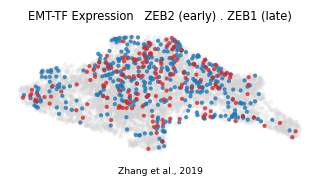

In [5]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [early_tf, late_tf]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [early_tf, late_tf]}
order = sorted([early_tf, late_tf], key=lambda g: -int(sel[g].sum()))
colors = {early_tf:'tab:blue', late_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title('EMT-TF Expression   %s (early) . %s (late)' % (early_tf, late_tf), size=7.5)
ax.text(.5,-.14,'Zhang et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
for g in [early_tf, late_tf]:
    m = sel[g]
    print('%s: %.1f%% expressing; %d shown (upper quartile), mean pseudotime of shown = %.2f (all = %.2f)' %
          (g, (_vec(g)>0).mean()*100, int(m.sum()), tn[m].mean(), tn.mean()))
print('saved expression.pdf')